In [1]:
import json, re
import numpy as np
import requests
import matplotlib.pyplot as plt
from matplotlib.path import Path
import astropy.units as u
from astropy.coordinates import SkyCoord, Distance
from astropy.time import Time
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import ImageNormalize, ZScaleInterval, AsinhStretch
from astroquery.ipac.irsa import Irsa

from app.config import get_settings  # same settings as the backend
cfg = get_settings()
TARGET = "eps Ind B"
FOV_ARCMIN = 6


In [2]:
xml = requests.get(cfg.sesame_url + requests.utils.quote(TARGET), timeout=30).text

def num(pattern):
    m = re.search(pattern, xml, re.S)
    return float(m.group(1)) if m else None

ra0, dec0 = num(r"<jradeg>([-\d.eE+]+)"), num(r"<jdedeg>([-\d.eE+]+)")
pmra, pmdec = num(r"<pmRA>([-\d.eE+]+)"), num(r"<pmDE>([-\d.eE+]+)")  # mas/yr  VERIFY tag names
plx = num(r"<plx>\s*<v>([-\d.eE+]+)")                                   # mas
print(ra0, dec0, pmra, pmdec, plx)  # if any is None, print(xml) and check the tags

star = SkyCoord(ra0 * u.deg, dec0 * u.deg,
                pm_ra_cosdec=(pmra or 0) * u.mas / u.yr, pm_dec=(pmdec or 0) * u.mas / u.yr,
                distance=Distance(parallax=plx * u.mas) if plx else 1 * u.kpc,
                obstime=Time("J2000"))

def position_at(mjd):
    return star.apply_space_motion(new_obstime=Time(mjd, format="mjd"))

print(position_at(61050))  # ~Jan 2026


331.04414658852124 -56.78284419511611 3981.977 -2466.832 270.658
<SkyCoord (ICRS): (ra, dec, distance) in (deg, deg, pc)
    (331.09671858, -56.80066604, 3.69469993)
 (pm_ra_cosdec, pm_dec, radial_velocity) in (mas / yr, mas / yr, km / s)
    (3983.86823288, -2463.77343116, 0.0484869)>


In [4]:
import time
from pyvo.dal import DALServiceError
from astropy.table import vstack

here = position_at(61050)
pos = (SkyCoord(here.ra, here.dec), 0.01 * u.deg)   # plain position, without distance/pm

def query_sia_retry(collection, tries=5):
    for i in range(tries):
        try:
            return Irsa.query_sia(pos=pos, collection=collection)
        except DALServiceError as e:
            print(f"{collection}: try {i + 1} failed ({str(e)[:60]}...)")
            time.sleep(2 * (i + 1))
    raise RuntimeError(f"IRSA SIA failed {tries} times for {collection}")

t = vstack([query_sia_retry(c) for c in cfg.sia_collections])
print(len(t), "rows")
print(t.colnames)


spherex_dr1: try 1 failed (Unable to access the capabilities endpoint at:
- https://irs...)
467 rows
['s_ra', 's_dec', 'facility_name', 'instrument_name', 'dataproduct_subtype', 'calib_level', 'dataproduct_type', 'energy_bandpassname', 'energy_emband', 'obs_id', 's_resolution', 'em_min', 'em_max', 'em_res_power', 'proposal_title', 'access_url', 'access_format', 'access_estsize', 't_exptime', 's_region', 'obs_collection', 'obs_intent', 'algorithm_name', 'facility_keywords', 'instrument_keywords', 'environment_photometric', 'proposal_id', 'proposal_pi', 'proposal_project', 'target_name', 'target_type', 'target_standard', 'target_moving', 'target_keywords', 'obs_release_date', 's_xel1', 's_xel2', 's_pixel_scale', 'position_timedependent', 't_min', 't_max', 't_resolution', 't_xel', 'obs_publisher_did', 's_fov', 'em_xel', 'pol_states', 'pol_xel', 'cloud_access', 'o_ucd', 'upload_row_id']


In [6]:
print(len(t))
t.group_by("obs_collection").groups.keys          # which collections
np.unique(t["obs_collection"], return_counts=True) # photos per collection
np.unique(t["energy_bandpassname"], return_counts=True)  # photos per detector
t[["obs_collection", "t_min", "energy_bandpassname", "em_min", "em_max"]]


467


obs_collection,t_min,energy_bandpassname,em_min,em_max
,d,,m,m
object,float64,object,float64,float64
spherex_dr1,60794.063320,SPHEREx-D6,4.4115e-06,5.0096e-06
spherex_dr1,60794.064813,SPHEREx-D6,4.4115e-06,5.0096e-06
spherex_dr1,60794.064813,SPHEREx-D3,1.6301e-06,2.4346e-06
spherex_dr1,60794.066305,SPHEREx-D6,4.4115e-06,5.0096e-06
spherex_dr1,60794.066305,SPHEREx-D3,1.6301e-06,2.4346e-06
spherex_dr1,60794.067797,SPHEREx-D6,4.4115e-06,5.0096e-06
spherex_dr1,60794.067797,SPHEREx-D3,1.6301e-06,2.4346e-06
spherex_dr1,60794.131591,SPHEREx-D3,1.6301e-06,2.4346e-06


In [12]:
row = t[len(t) // 2]
key = json.loads(row["cloud_access"])["aws"]["key"]
url = cfg.s3_https_base + key
print(url)

hdul = fits.open(url, use_fsspec=True, lazy_load_hdus=True)  # only reads what you touch
hdul.info()


https://nasa-irsa-spherex.s3.amazonaws.com/dr1/level2/2025W42_1A/l2b-v27-2026-243/4/level2_2025W42_1A_0124_1D4_spx_l2b-v27-2026-243.fits
Filename: <class 'fsspec.implementations.http.HTTPFile'>
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       275   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     56   441R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [13J, 20J, 520E]   


In [8]:
h = hdul["IMAGE"].header
for k in ["MJD-AVG", "XPOSURE", "DETECTOR", "PSF_FWHM", "SPS_EPA", "BUNIT", "L2DQAFLG", "VERSION"]:
    print(f"{k:10s}", h.get(k, "—"))


MJD-AVG    60961.432951803
XPOSURE    113.5826
DETECTOR   4
PSF_FWHM   8.672612363488842
SPS_EPA    180.0
BUNIT      MJy / sr
L2DQAFLG   Pass
VERSION    —


target at x=1211.7, y=1301.4


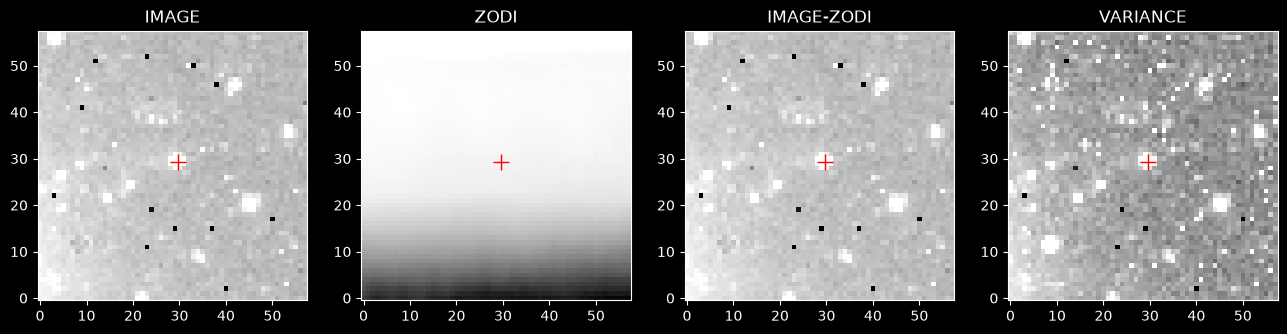

In [10]:
c = position_at(h["MJD-AVG"])
w = WCS(h)
x, y = w.world_to_pixel(c)            # 0-based
half = int(FOV_ARCMIN * 60 / cfg.pixel_scale_arcsec / 2)
r0, r1 = int(y) - half, int(y) + half
c0, c1 = int(x) - half, int(x) + half
print(f"target at x={x:.1f}, y={y:.1f}")

cut = {e: hdul[e].section[r0:r1, c0:c1] for e in ["IMAGE", "ZODI", "VARIANCE"]}
cut["IMAGE-ZODI"] = cut["IMAGE"] - cut["ZODI"]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, name in zip(ax, ["IMAGE", "ZODI", "IMAGE-ZODI", "VARIANCE"]):
    norm = ImageNormalize(cut[name], interval=ZScaleInterval(), stretch=AsinhStretch())
    a.imshow(cut[name], origin="lower", norm=norm, cmap="gray")
    a.plot(x - c0, y - r0, "r+", ms=12)
    a.set_title(name)
plt.show()  # detector orientation, not north-up yet


{0: 'TRANSIENT', 1: 'OVERFLOW', 2: 'SUR_ERROR', 6: 'NONFUNC', 7: 'DICHROIC', 9: 'MISSING_DATA', 10: 'HOT', 11: 'COLD', 12: 'FULLSAMPLE', 14: 'PHANMISS', 15: 'NONLINEAR', 17: 'PERSIST', 19: 'OUTLIER', 20: 'CROSSTALK', 21: 'SOURCE', 22: 'GHOST', 23: 'GHOST_FPA', 24: 'GHOST_EXT', 25: 'STREAK', 26: 'BLOOM', 27: 'SNOWBALL', 28: 'HALO'}
bit  0 TRANSIENT           30 px  (0.9 %)
bit  1 OVERFLOW             6 px  (0.2 %)
bit  2 SUR_ERROR           31 px  (0.9 %)
bit  6 NONFUNC             30 px  (0.9 %)
bit 11 COLD                 2 px  (0.1 %)
bit 17 PERSIST              1 px  (0.0 %)
bit 19 OUTLIER             43 px  (1.3 %)
bit 21 SOURCE            2450 px  (72.8 %)
bit 28 HALO                51 px  (1.5 %)
official recipe removes 2.4 % of the cutout


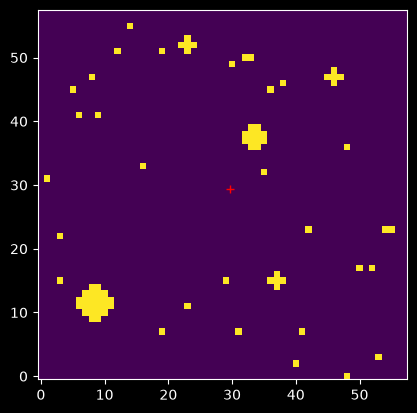

In [14]:
fh = hdul["FLAGS"].header
bits = {int(k[4:]): v for k, v in fh.items() if k.startswith("MSKN")}  # VERIFY: number = bit index?
print(bits)

flags = hdul["FLAGS"].section[r0:r1, c0:c1].astype(np.int64)
for b, name in sorted(bits.items()):
    n = int(((flags >> b) & 1).sum())
    if n:
        print(f"bit {b:2d} {name:16s} {n:5d} px  ({100 * n / flags.size:.1f} %)")

EXCLUDE = ["SUR_ERROR", "NONFUNC", "MISSING_DATA", "HOT", "COLD", "NONLINEAR",
           "PERSIST", "BLOOM", "SNOWBALL", "HALO", "SATELLITE_HALO"]
bad = sum(1 << b for b, n in bits.items() if n in EXCLUDE)
mask = (flags & bad) != 0
print(f"official recipe removes {100 * mask.mean():.1f} % of the cutout")
plt.imshow(mask, origin="lower"); plt.plot(x - c0, y - r0, "r+"); plt.show()


In [15]:
wl = WCS(h, fobj=hdul, key="W")
wl.sip = None
print(wl.pixel_to_world_values(x, y))  # VERIFY: (λ µm, bandwidth µm)?


INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
(array(2.81836797), 

{'XCENTER': np.float32(1213.7858), 'YCENTER': np.float32(1310.9286), 'CWAVE': np.float32(2.812196), 'NSTAR': np.int32(350)}


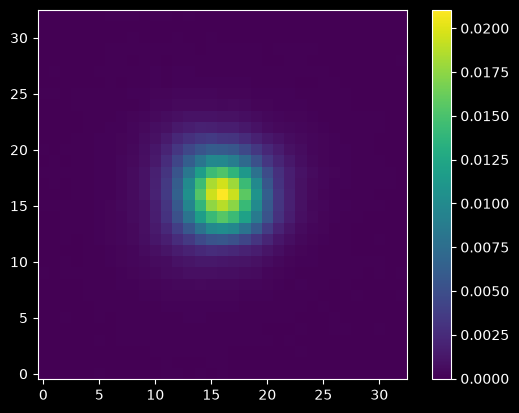

In [16]:
ep = hdul["EPSF"].data
i = np.argmin((ep["XCENTER"] - x) ** 2 + (ep["YCENTER"] - y) ** 2)
print({k: ep[k][i] for k in ["XCENTER", "YCENTER", "CWAVE", "NSTAR"]})
plt.imshow(ep["EPSF"][i], origin="lower"); plt.colorbar(); plt.show()


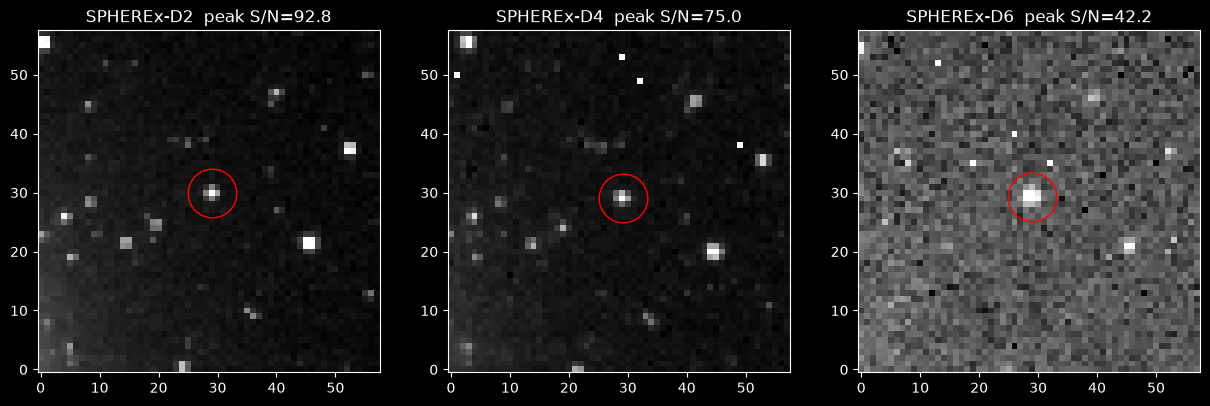

In [24]:
from astropy.visualization import PercentileInterval

    
    
def show(row, ax, title=""):
    url = cfg.s3_https_base + json.loads(row["cloud_access"])["aws"]["key"]
    hd = fits.open(url, use_fsspec=True, lazy_load_hdus=True)
    hh = hd["IMAGE"].header
    x, y = map(float, WCS(hh).world_to_pixel(position_at(hh["MJD-AVG"])))

    r0, c0 = int(y) - half, int(x) - half
    img = hd["IMAGE"].section[r0:r0 + 2 * half, c0:c0 + 2 * half]
    var = hd["VARIANCE"].section[r0:r0 + 2 * half, c0:c0 + 2 * half]
    yy, xx = int(round(y)) - r0, int(round(x)) - c0
    snr = (img[yy, xx] - np.nanmedian(img)) / np.sqrt(var[yy, xx])
    ax.imshow(img, origin="lower", cmap="gray",
              norm=ImageNormalize(img, interval=PercentileInterval(99.5), stretch=AsinhStretch(0.1)))
    ax.plot(x - c0, y - r0, "o", mfc="none", mec="r", ms=35, mew=1)


    ax.set_title(f"{title}  peak S/N={snr:.1f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, det in zip(ax, ["SPHEREx-D2", "SPHEREx-D4", "SPHEREx-D6"]):
    rows = t[t["energy_bandpassname"] == det]
    show(rows[len(rows) // 2], a, det)
plt.show()


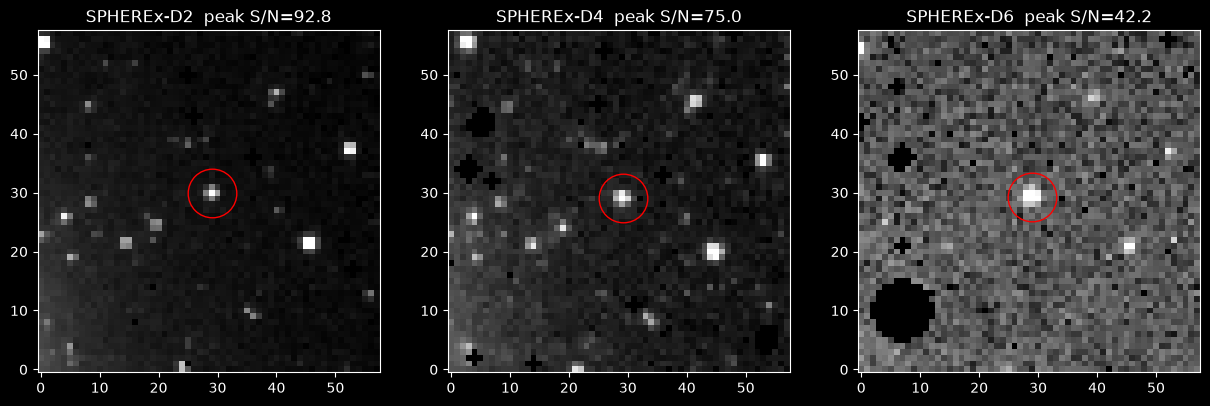

In [25]:
from astropy.visualization import PercentileInterval

    
    
def show(row, ax, title=""):
    url = cfg.s3_https_base + json.loads(row["cloud_access"])["aws"]["key"]
    hd = fits.open(url, use_fsspec=True, lazy_load_hdus=True)
    hh = hd["IMAGE"].header
    x, y = map(float, WCS(hh).world_to_pixel(position_at(hh["MJD-AVG"])))

    r0, c0 = int(y) - half, int(x) - half
    img = hd["IMAGE"].section[r0:r0 + 2 * half, c0:c0 + 2 * half]          # the image (you already have this)
    flags = hd["FLAGS"].section[r0:r0 + 2 * half, c0:c0 + 2 * half].astype(np.int64)  # NEW: flags of the same cutout
    img = np.where((flags & bad) != 0, np.nan, img)                          # NEW: bad pixel -> NaN

    var = hd["VARIANCE"].section[r0:r0 + 2 * half, c0:c0 + 2 * half]
    yy, xx = int(round(y)) - r0, int(round(x)) - c0
    snr = (img[yy, xx] - np.nanmedian(img)) / np.sqrt(var[yy, xx])
    ax.imshow(img, origin="lower", cmap="gray",
              norm=ImageNormalize(img, interval=PercentileInterval(99.5), stretch=AsinhStretch(0.1)))
    ax.plot(x - c0, y - r0, "o", mfc="none", mec="r", ms=35, mew=1)


    ax.set_title(f"{title}  peak S/N={snr:.1f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, det in zip(ax, ["SPHEREx-D2", "SPHEREx-D4", "SPHEREx-D6"]):
    rows = t[t["energy_bandpassname"] == det]
    show(rows[len(rows) // 2], a, det)
plt.show()

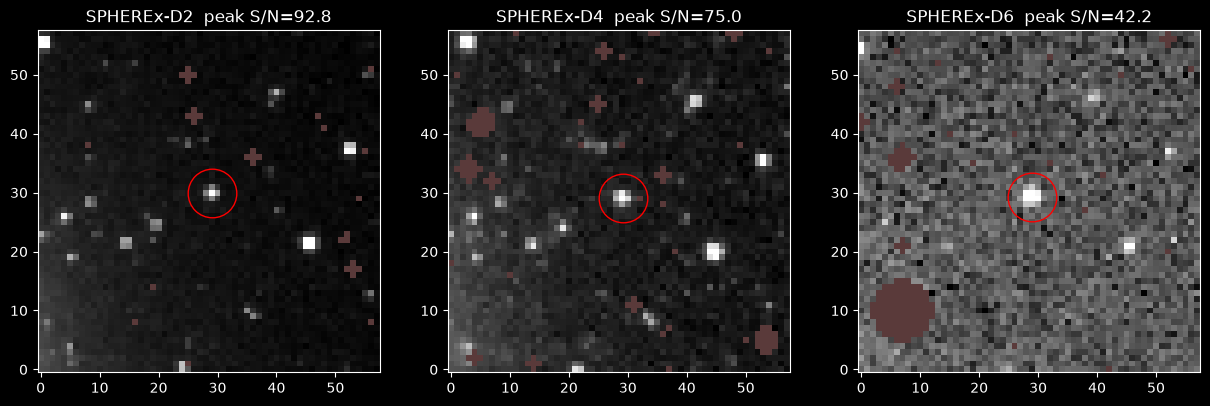

D6 big disc : ['TRANSIENT', 'OVERFLOW', 'SOURCE', 'SNOWBALL', 'HALO']
D4 cross    : ['SOURCE']
target D2   : ['SOURCE']


In [26]:
from astropy.visualization import PercentileInterval

HALF = 29  # half-size of the cutout in pixels (~6 arcmin total)
EXCLUDE = ["SUR_ERROR", "NONFUNC", "MISSING_DATA", "HOT", "COLD", "NONLINEAR",
           "PERSIST", "BLOOM", "SNOWBALL", "HALO", "SATELLITE_HALO"]  # official recipe

CMAP = plt.cm.gray.copy()
CMAP.set_bad("#5a3a3a")  # masked pixels: explicit colour, never confused with empty sky


def load_cutout(row, half=HALF):
    """Read IMAGE, VARIANCE and FLAGS around the target for one SIA row (lazy reads from S3)."""
    url = cfg.s3_https_base + json.loads(row["cloud_access"])["aws"]["key"]
    hd = fits.open(url, use_fsspec=True, lazy_load_hdus=True)
    hh = hd["IMAGE"].header
    x, y = map(float, WCS(hh).world_to_pixel(position_at(hh["MJD-AVG"])))
    r0, c0 = int(y) - half, int(x) - half
    sl = (slice(r0, r0 + 2 * half), slice(c0, c0 + 2 * half))

    bits = {int(k[4:]): v for k, v in hd["FLAGS"].header.items() if k.startswith("MSKN")}
    bad = sum(1 << b for b, name in bits.items() if name in EXCLUDE)

    img = hd["IMAGE"].section[sl]
    var = hd["VARIANCE"].section[sl]
    flags = hd["FLAGS"].section[sl].astype(np.int64)
    masked = np.where((flags & bad) != 0, np.nan, img)

    return dict(img=img, masked=masked, var=var, flags=flags, bits=bits,
                x=x - c0, y=y - r0, mjd=hh["MJD-AVG"], url=url)


def peak_snr(c):
    yy, xx = int(round(c["y"])), int(round(c["x"]))
    return (c["img"][yy, xx] - np.nanmedian(c["masked"])) / np.sqrt(c["var"][yy, xx])


def show(c, ax, title=""):
    norm = ImageNormalize(c["masked"], interval=PercentileInterval(99.5), stretch=AsinhStretch(0.1))
    ax.imshow(c["masked"], origin="lower", cmap=CMAP, norm=norm)
    ax.plot(c["x"], c["y"], "o", mfc="none", mec="r", ms=35, mew=1)
    ax.set_title(f"{title}  peak S/N={peak_snr(c):.1f}")


def which_bits(c, col, row):
    """Flag names set on one pixel of the cutout (col = x, row = y as in the plot)."""
    v = int(c["flags"][row, col])
    return [c["bits"][b] for b in sorted(c["bits"]) if (v >> b) & 1]


# --- same point, three detectors ---------------------------------------------------------
out = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, det in zip(ax, ["SPHEREx-D2", "SPHEREx-D4", "SPHEREx-D6"]):
    rows = t[t["energy_bandpassname"] == det]
    out[det] = load_cutout(rows[len(rows) // 2])
    show(out[det], a, det)
plt.show()

# --- what is each masked shape? (adjust the pixels to the ones you see) -------------------
print("D6 big disc :", which_bits(out["SPHEREx-D6"], 7, 10))
print("D4 cross    :", which_bits(out["SPHEREx-D4"], 5, 27))
print("target D2   :", which_bits(out["SPHEREx-D2"], round(out["SPHEREx-D2"]["x"]), round(out["SPHEREx-D2"]["y"])))
